# ЛАБОРАТОРНА РОБОТА № 4

## Візуальний аналіз даних та часові ряди — аналіз у двох середовищах

**Курс:** СК26 «Інтелектуальний аналіз та візуалізація даних»
**Кафедра систем штучного інтелекту, Національний університет «Львівська політехніка»**
**Оцінювання:** 4 бали

---

## Визначення варіанта

Заповніть три поля в клітинці нижче й виконайте обидві службові клітинки —
номер варіанта, ринок і товар визначаться автоматично.

In [1]:
# ── Заповніть три поля ──────────────────────────────────────────
SURNAME_NAME = 'Штурин Захарій'      # прізвище та ім'я
GROUP        = 'ШІ-34'               # шифр групи, наприклад СШІ-31
NUMBER       = 6                     # ваш номер за списком групи (1–30)

assert SURNAME_NAME.strip(), 'Впишіть прізвище та ім\'я'
assert GROUP.strip(),        'Впишіть групу'
assert isinstance(NUMBER, int) and 1 <= NUMBER <= 30, 'Номер має бути цілим від 1 до 30'
print('Дані прийнято:', SURNAME_NAME, '|', GROUP, '| номер', NUMBER)

Дані прийнято: Штурин Захарій | ШІ-34 | номер 6


In [2]:
# ── Службова клітинка: визначення варіанта. Змінювати не потрібно ──
import json
%matplotlib widget

VARIANTS = json.load(open('lr4_variants_student.json', encoding='utf-8'))
V = VARIANTS[NUMBER - 1]

MARKET, GOOD, GOOD_UA = V['ринок'], V['товар'], V['товар_укр']

print('=' * 72)
print(f'ВАРІАНТ {V["варіант"]}   ·   {SURNAME_NAME}   ·   {GROUP}')
print('=' * 72)
print()
print(f'   Ринок:  {MARKET}')
print(f'   Товар:  {GOOD_UA}   (у наборі даних: {GOOD})')
print()
print('Далі в роботі користуйтеся змінними MARKET і GOOD —')
print('тоді весь код автоматично працюватиме саме з вашим рядом.')
print()
print('Період: 03.2014 – 12.2017 · очікувана довжина ряду: 46 місяців')
print('Фолдів ретроспективної перевірки: 7 · горизонт: 3 місяці · ARIMA(1, 1, 1)')

ВАРІАНТ 6   ·   Штурин Захарій   ·   ШІ-34

   Ринок:  Cherkasy
   Товар:  молоко   (у наборі даних: Milk - Retail)

Далі в роботі користуйтеся змінними MARKET і GOOD —
тоді весь код автоматично працюватиме саме з вашим рядом.

Період: 03.2014 – 12.2017 · очікувана довжина ряду: 46 місяців
Фолдів ретроспективної перевірки: 7 · горизонт: 3 місяці · ARIMA(1, 1, 1)


> ⚠️ Якщо ці дві клітинки не виконано, усі подальші завдання не мають сенсу:
> перевіряти роботу будуть **за вашим варіантом**, а не за тим рядом, який ви оберете самі.

| | |
|---|---|
| **Дата здачі** |28 жовтня |
| **Підпис** | ЗШ |

---
## Мета роботи

Виконати повний цикл аналізу одного часового ряду **у двох середовищах** — у Python та в Orange —
і пояснити, чому однаково названі метрики в них дають різні числа.

## Вихідні дані

| Файл | Зміст |
|---|---|
| `ціни_україна_2014_2017.csv` | Роздрібні ціни на 25 товарів по 28 ринках України, щомісяця, 03.2014 – 12.2017 |
| `lr4_variants_student.json` | Розподіл варіантів (зчитується автоматично) |
| `ЛР4_помилковий_аналіз.ipynb` | Звіт колеги, який треба відрецензувати (завдання 8) |

Це той самий набір, з яким ми працювали на лекції 4. **Національне середнє в завданнях не використовується** —
ваш ряд це конкретний обласний ринок.

## Що здавати

1. **`ЛР4_Прізвище_Варіант.ipynb`** — цей зошит із вашим кодом, графіками та письмовими висновками.
2. **`ряд_для_orange.csv`** — експортований ряд (завдання 9).
3. **`потік_orange.ows`** — збережений потік Orange.
4. **Знімки екрана** з Orange для завдань 10–13 — вставте їх у зошит або додайте окремими файлами.

## Правила

* **Код пишете самостійно** — у цьому зошиті навмисно немає заготовок.
* **Користуватися штучним інтелектом дозволено**, але ви зобов'язані заповнити декларацію в кінці зошита.
* **Кожне число має супроводжуватися висновком словами.** Робота, у якій є графіки й таблиці,
  але немає письмових відповідей на поставлені питання, оцінюється як невиконана.
* Усі обчислення мають бути **відтворюваними**: зошит має виконуватися від початку до кінця
  командою *Restart & Run All* без помилок.

---
# ЧАСТИНА 1. Аналіз засобами Python

*Виконується аудиторно.*

## Завдання 1. Підготовка ряду

Витягніть із набору ряд свого варіанта — скористайтеся змінними `MARKET` і `GOOD`,
які визначилися у службовій клітинці, — і приведіть його до **повної місячної сітки**
з березня 2014 по грудень 2017.

**У звіті наведіть:**
1. скільки місяців у сітці та скільки з них мають вимір;
2. у якому саме місяці пропуск;
3. **чому** цей пропуск виник — і чи він у вашому ряді один.

> 💡 **Підказка.** Пропуск є в усіх без винятку рядах набору. Якщо ви знайшли більше одного — перевірте, чи правильно побудована сітка.

In [3]:
# Завдання 1. Підготовка ряду
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings('ignore')

prices = pd.read_csv('ціни_україна_2014_2017.csv')
prices['date'] = pd.to_datetime(dict(year=prices['рік'], month=prices['місяць'], day=1))

mine = prices[(prices['ринок'] == MARKET) & (prices['товар'] == GOOD)]
GRID = pd.date_range('2014-03-01', '2017-12-01', freq='MS')
raw = mine.set_index('date')['ціна'].sort_index().reindex(GRID)
GAPS = raw[raw.isna()].index

print('Місяців у сітці:', len(GRID))
print('Місяців із виміром:', raw.notna().sum())
print('Пропущені місяці:', list(GAPS.strftime('%m.%Y')))
print('Місяці, яких немає в усьому наборі:', [d.strftime('%m.%Y') for d in GRID if d not in set(prices['date'])])

Місяців у сітці: 46
Місяців із виміром: 45
Пропущені місяці: ['08.2017']
Місяці, яких немає в усьому наборі: ['08.2017']


**Висновок до завдання 1:**

1. Сітка - 46 місяців, вимір є для 45.
2. Пропущено один місяць - **08.2017**.
3. Пропуск не пов'язаний з моїм рядом: за 08.2017 у всьому наборі немає жодного рядка (жоден ринок, жоден товар). Пропуск один.

## Завдання 2. Заповнення пропуску

Заповніть пропуск. Порівняйте **щонайменше три** способи: перенесення останнього значення,
лінійну інтерполяцію та ще один на ваш вибір.

**У звіті наведіть:**
1. значення, яке дає кожен спосіб;
2. який спосіб ви обрали і **чому саме його**;
3. за якої умови заповнювати пропуск було б **неприпустимо** — наведіть приклад із цього ж набору даних.

> 💡 **Підказка.** Третій пункт стосується не вашого ряду, а принципу. Згадайте, які області зникають із набору у 2014 році.

In [4]:
# Завдання 2. Заповнення пропуску
GAP = GAPS[0]
print('ffill:', round(raw.ffill()[GAP], 3))
print('лінійна інтерполяція:', round(raw.interpolate()[GAP], 3))
print('кубічний сплайн:', round(raw.interpolate(method='spline', order=3)[GAP], 3))

y = raw.interpolate().round(4)

ffill: 16.917
лінійна інтерполяція: 16.872
кубічний сплайн: 17.17


**Висновок до завдання 2:**

1. Значення для 08.2017: ffill - 16.917, лінійна інтерполяція - 16.872, кубічний сплайн - 17.170 грн/л.
2. Обрано лінійну інтерполяцію: пропуск один, усередині спокійної ділянки, і вона враховує обох сусідів. Сплайн "перелітає" обидва сусідні значення, а ffill ігнорує вересень.
3. Заповнювати неприпустимо, коли пропуск спричинений самою подією (не випадковий). Приклад: Луганська (08–12.2014), Донецька (08, 09, 12.2014), Крим і Севастополь (після 03–04.2014) - інтерполяція вигадала б ціни саме тоді, коли ринки були зруйновані чи окуповані.

## Завдання 3. Візуальна розвідка

Побудуйте **не менше трьох** графіків свого ряду, які відповідають на різні питання.

**У звіті наведіть:**
1. для кожного графіка — яке питання він ставить і **чому обрано саме таку геометрію та шкалу**;
2. одну знахідку, якої ви не очікували до побудови графіків.

> 💡 **Підказка.** Графік без пояснення вибору форми не зараховується. Нагадування з лекції: геометрія — це твердження про дані.

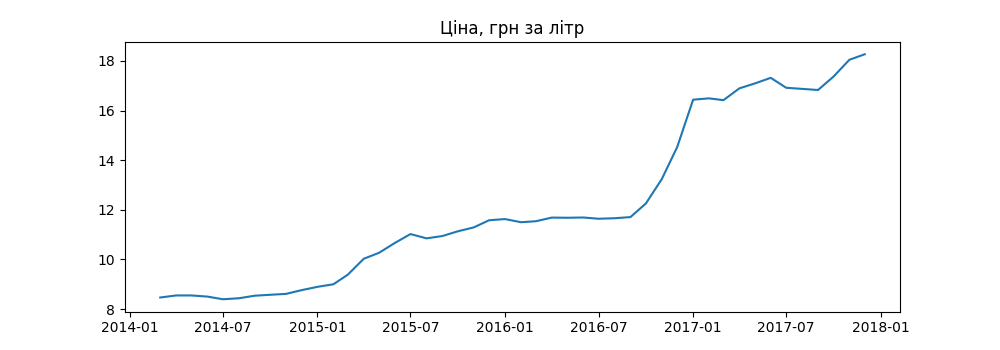

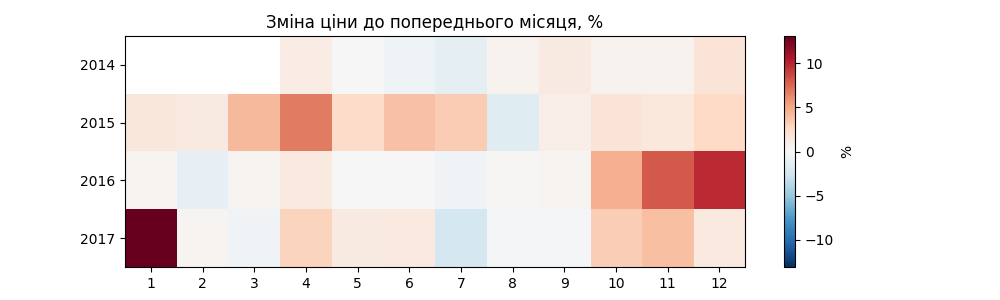

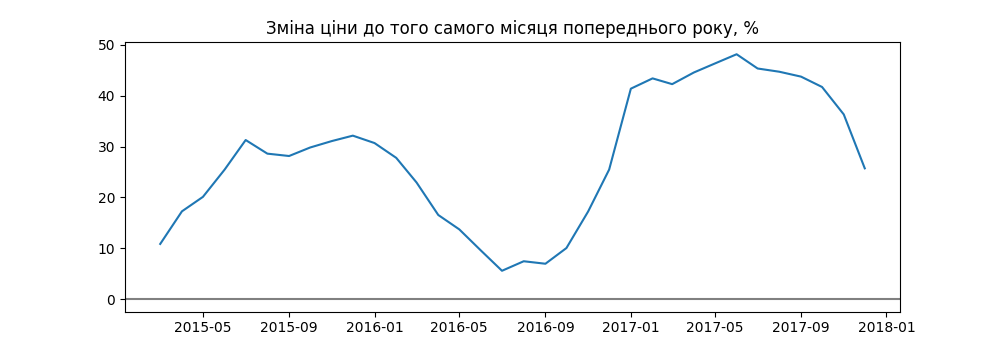

In [5]:
# Завдання 3. Візуальна розвідка
# Графік 1. Рівень ціни в часі
plt.figure(figsize=(10, 3.5))
plt.plot(y)
plt.title('Ціна, грн за літр')
plt.show()

# Графік 2. Місячні зміни: рік × місяць
mom = y.pct_change() * 100
heat = mom.groupby([mom.index.year, mom.index.month]).first().unstack()
lim = np.nanmax(np.abs(heat.values))
plt.figure(figsize=(10, 3))
plt.imshow(heat.values, cmap='RdBu_r', vmin=-lim, vmax=lim, aspect='auto')
plt.xticks(range(12), range(1, 13)); plt.yticks(range(len(heat)), heat.index)
plt.colorbar(label='%')
plt.title('Зміна ціни до попереднього місяця, %')
plt.show()

# Графік 3. Річний темп зростання
yoy = (y / y.shift(12) - 1).dropna() * 100
plt.figure(figsize=(10, 3.5))
plt.plot(yoy); plt.axhline(0, color='grey')
plt.title('Зміна ціни до того самого місяця попереднього року, %')
plt.show()


**Висновок до завдання 3:**

| № | Питання | Геометрія і шкала |
|---|---|---|
| 1 | Як змінювалась ціна і де стрибки? | Лінія - неперервний час; лінійна шкала в грн, бо діапазон лише ~2x (8.4 - 18.3). |
| 2 | Чи є сезонність? | Теплова карта рік x місяць - легко порівняти той самий місяць у різні роки; розбіжна шкала з нулем у центрі, бо % зміни мають знак. |
| 3 | Як змінювався темп подорожчання? | Лінія річного темпу з нульовою опорою - порівняння з тим самим місяцем прибирає сезонність. |

Найбільший стрибок - не девальваційний 2015 рік, а 10.2016 - 01.2017. Дев'ять місяців 2016 року ціна стояла майже на місці, потім за 4 місяці зросла на ~40 % і назад не повернулася.

## Завдання 4. Розкладання на складові

Розкладіть ряд на тренд, сезонну складову та залишок методом STL із періодом 12.

**У звіті наведіть:**
1. чотирипанельний графік розкладання;
2. числові значення сили сезонності $F_S$ та сили тренду $F_T$;
3. **висновок: чи є у вашому ряді сезонність**, із посиланням на порогове значення.

> 💡 **Підказка.** STL поверне сезонну складову завжди. Ваше завдання — вирішити, чи вона означає щось, а не чи вона є.

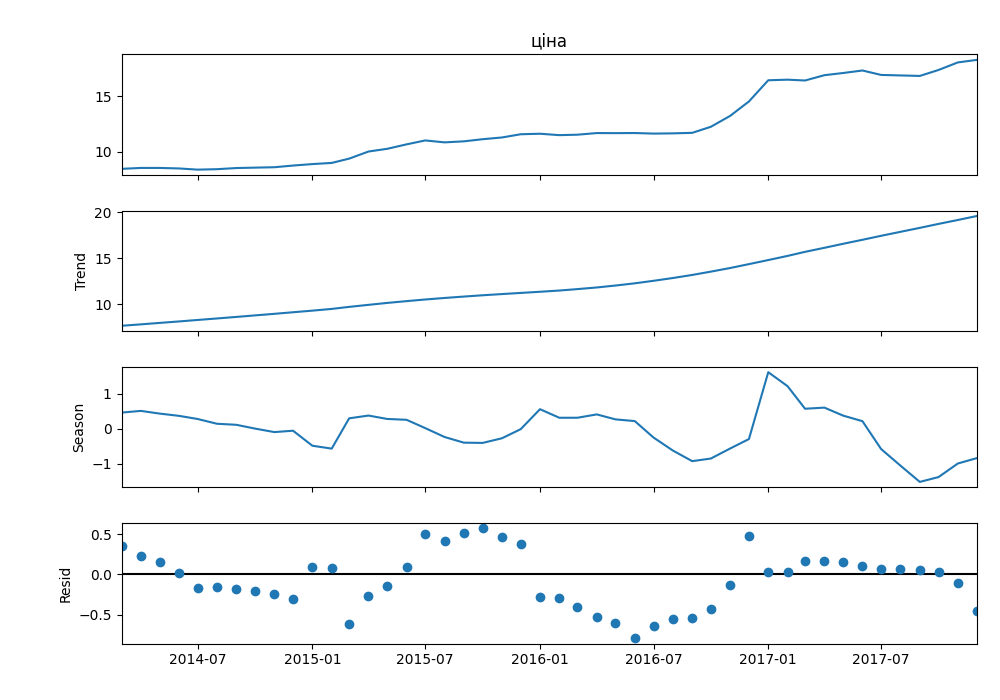

F_T = 0.99
F_S = 0.764 (поріг 0.64)


In [6]:
# Завдання 4. Розкладання на складові
from statsmodels.tsa.seasonal import STL

stl = STL(y, period=12, robust=True).fit()
T, S, R = stl.trend, stl.seasonal, stl.resid
stl.plot().set_size_inches(10, 7)
plt.show()

F_S = max(0, 1 - R.var() / (S + R).var())
F_T = max(0, 1 - R.var() / (T + R).var())
print('F_T =', round(F_T, 3))
print('F_S =', round(F_S, 3), '(поріг 0.64)')

**Висновок до завдання 4:**

1. Графік STL наведено вище.
2. $F_T = 0.990$, $F_S = 0.764$.
3. Формально $F_S$ > 0.64, але значущої сезонності немає: на графіку сезонна складова з року в рік зростає - STL "розмазав" по ній стрибок 2016 року;

## Завдання 5. Стаціонарність

Побудуйте ACF і PACF вихідного ряду та його першої різниці. Застосуйте тести ADF і KPSS до обох.

**У звіті наведіть:**
1. графіки ACF і PACF до та після диференціювання;
2. таблицю з $p$-значеннями обох тестів для обох рядів;
3. висновок про стаціонарність **із зазначенням, узгоджуються тести між собою чи ні**;
4. якщо не узгоджуються — ваше пояснення, чому.

> 💡 **Підказка.** Нульові гіпотези ADF і KPSS протилежні. Перш ніж писати висновок, перевірте, що ви не переплутали напрямок.

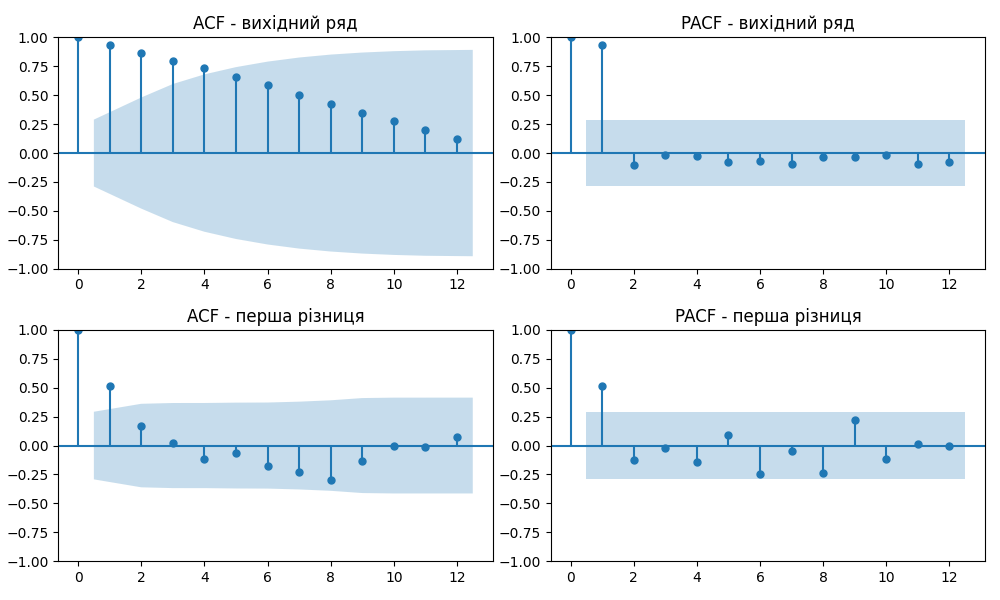

,ADF p,KPSS p
вихідний ряд,0.959,0.01
перша різниця,0.004,0.10


In [7]:
# Завдання 5. Стаціонарність
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller, kpss
warnings.simplefilter('ignore')

dy = y.diff().dropna()
LAGS = 12
fig, axes = plt.subplots(2, 2, figsize=(10, 6))
plot_acf(y, lags=LAGS, ax=axes[0, 0], title='ACF - вихідний ряд')
plot_pacf(y, lags=LAGS, ax=axes[0, 1], title='PACF - вихідний ряд')
plot_acf(dy, lags=LAGS, ax=axes[1, 0], title='ACF - перша різниця')
plot_pacf(dy, lags=LAGS, ax=axes[1, 1], title='PACF - перша різниця')
plt.tight_layout(); plt.show()

stationarity = pd.DataFrame({
    'ADF p': [adfuller(y)[1], adfuller(dy)[1]],
    'KPSS p': [kpss(y, nlags='auto')[1], kpss(dy, nlags='auto')[1]],
}, index=['вихідний ряд', 'перша різниця'])
stationarity.round(3)

**Висновок до завдання 5:**

1. Графіки наведено вище: ACF вихідного ряду спадає повільно (тренд), після диференціювання значущий лише лаг 1.
2. Таблиця:

   | ряд | ADF $p$ | KPSS $p$ |
   |---|---|---|
   | вихідний | 0.959 - нестаціонарний | < 0.01 - нестаціонарний |
   | перша різниця | 0.004 - стаціонарний | > 0.10 - стаціонарний |

3. Тести узгоджуються: вихідний ряд нестаціонарний, перша різниця стаціонарна - d = 1.
4. Розбіжності немає.

## Завдання 6. Базисні прогнози та ретроспективна перевірка

Побудуйте **чотири** базисні прогнози: наївний, сезонний наївний, середнє та дрейф.
Оцініть їх **ретроспективною перевіркою з рухомим початком**: **7 фолдів по 3 кроки**,
навчальна частина розширюється.

**У звіті наведіть:**
1. таблицю MAE, RMSE і MAPE для всіх чотирьох базисів;
2. який базис виявився найкращим і **чому саме він** — поясніть через властивості вашого ряду;
3. для порівняння: ту саму оцінку, зроблену звичайним випадковим поділом 75/25, і **у скільки разів** вона відрізняється.

> 💡 **Підказка.** Кількість фолдів і кроків задана жорстко — у Частині 2 вона має збігтися з налаштуваннями Orange.

In [8]:
# Завдання 6. Базисні прогнози та ретроспективна перевірка
N_FOLDS, H = 7, 3
v = y.values

def forecast(method, train, h):
    if method == 'наївний':
        return np.repeat(train[-1], h)
    if method == 'сезонний наївний':
        return np.array([train[len(train) - 12 + j % 12] for j in range(h)])
    if method == 'середнє':
        return np.repeat(train.mean(), h)
    if method == 'дрейф':
        slope = (train[-1] - train[0]) / (len(train) - 1)
        return train[-1] + slope * np.arange(1, h + 1)

def folds(n, n_folds=N_FOLDS, h=H):
    for k in range(n_folds, 0, -1):
        yield n - k * h, n - (k - 1) * h

def scores(true, pred):
    e = np.asarray(true) - np.asarray(pred)
    return {'MAE': np.abs(e).mean(), 'RMSE': np.sqrt((e ** 2).mean()),
            'MAPE, %': np.mean(np.abs(e / true)) * 100}

def rolling_origin(fc_fn):
    true, pred = [], []
    for end, stop in folds(len(v)):
        true += list(v[end:stop]); pred += list(fc_fn(v[:end], stop - end))
    return np.array(true), np.array(pred)

BASELINES = ['наївний', 'сезонний наївний', 'середнє', 'дрейф']
cv = {m: rolling_origin(lambda tr, h, m=m: forecast(m, tr, h)) for m in BASELINES}
cv_table = pd.DataFrame({m: scores(*cv[m]) for m in BASELINES}).T
print(cv_table.round(3))

from sklearn.model_selection import train_test_split
idx_tr, idx_te = train_test_split(np.arange(len(v)), test_size=0.25, random_state=42)
idx_tr = np.sort(idx_tr)

def random_split_forecast(method, t):
    prev = idx_tr[idx_tr < t]
    if method == 'наївний':
        return v[prev[-1]] if len(prev) else np.nan
    if method == 'сезонний наївний':
        return v[t - 12] if t - 12 in idx_tr else np.nan
    if method == 'середнє':
        return v[idx_tr].mean()
    if method == 'дрейф':
        slope = (v[idx_tr[-1]] - v[idx_tr[0]]) / (idx_tr[-1] - idx_tr[0])
        return v[prev[-1]] + slope * (t - prev[-1]) if len(prev) else np.nan

rand_mae = {}
for m in BASELINES:
    p = np.array([random_split_forecast(m, t) for t in idx_te]); ok = ~np.isnan(p)
    rand_mae[m] = scores(v[idx_te][ok], p[ok])['MAE']
comparison = pd.DataFrame({'MAE рухомий початок': cv_table['MAE'], 'MAE випадковий 75/25': pd.Series(rand_mae)})
comparison['у скільки разів'] = comparison.iloc[:, 0] / comparison.iloc[:, 1]
comparison.round(3)

                    MAE   RMSE  MAPE, %
наївний           0.846  1.147    5.361
сезонний наївний  3.451  3.936   21.483
середнє           4.353  4.763   27.552
дрейф             0.737  0.975    4.769


,MAE рухомий початок,MAE випадковий 75/25,у скільки разів
наївний,0.846,0.178,4.747
сезонний наївний,3.451,3.518,0.981
середнє,4.353,3.248,1.340
дрейф,0.737,0.260,2.837


**Висновок до завдання 6:**

1. Рухомий початок 7 × 3:

   | базис | MAE | RMSE | MAPE, % |
   |---|---|---|---|
   | наївний | 0.846 | 1.147 | 5.36 |
   | сезонний наївний | 3.451 | 3.936 | 21.48 |
   | середнє | 4.353 | 4.763 | 27.55 |
   | дрейф | 0.737 | 0.975 | 4.77 |

2. Найкращий - дрейф: ряд має одиничний корінь і сильний тренд, тож найкраще - останнє значення плюс середній приріст. Середнє й сезонний наївний відстають від тренду.
3. Випадковий поділ 75/25 дає оманливо малу MAE: для наївного у 4.7 раза менше, для дрейфу - у 2.8 раза. Причина - витік майбутнього в навчання.

## Завдання 7. Модель ARIMA

Побудуйте модель ARIMA і оцініть її **на тих самих 7 фолдах по 3 кроки**.

Обов'язково використайте порядок **(1, 1, 1)** — саме його ви відтворюватимете в Orange.
Додатково визначте, який порядок $(p, d, q)$ ви обрали б **за виглядом ACF і PACF** із завдання 5.

**У звіті наведіть:**
1. MAE, RMSE і MAPE моделі ARIMA(1,1,1) на рухомому початку;
2. обґрунтування порядку, який ви обрали б самостійно, з посиланням на конкретні лаги;
3. **порівняння з найкращим базисом із завдання 6** — і прямий висновок, чи має ця модель право на існування;
4. графік залишків моделі та висновок, чи лишилася в них структура.

> 💡 **Підказка.** Якщо ARIMA програла базису — це законний результат, а не помилка. Напишіть про це прямо.

                MAE   RMSE  MAPE, %
ARIMA(1,1,1)  0.706  0.956    4.496
дрейф         0.737  0.975    4.769


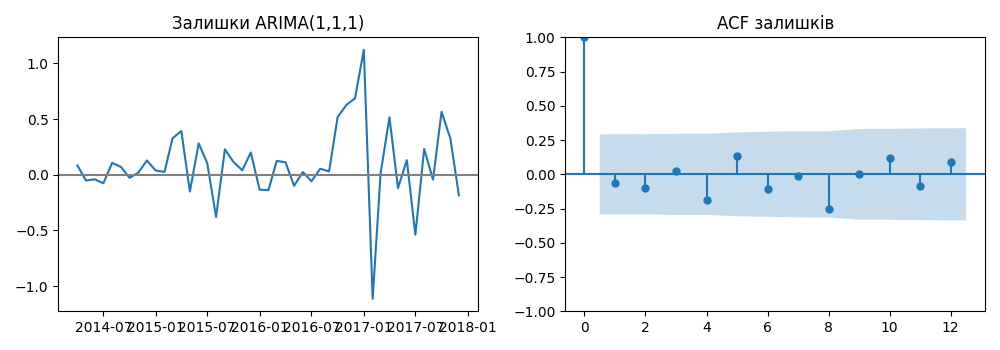

In [9]:
# Завдання 7. Модель ARIMA
from statsmodels.tsa.arima.model import ARIMA

def fit_arima(x, order):
    return ARIMA(x, order=order).fit()

cv['ARIMA(1,1,1)'] = rolling_origin(lambda tr, h: fit_arima(tr, (1, 1, 1)).forecast(h))
arima_table = pd.DataFrame({m: scores(*cv[m]) for m in ['ARIMA(1,1,1)', 'дрейф']}).T
print(arima_table.round(3))

fit = fit_arima(v, (1, 1, 1))
resid = pd.Series(fit.resid[1:], index=GRID[1:])

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].plot(resid); axes[0].axhline(0, color='grey'); axes[0].set_title('Залишки ARIMA(1,1,1)')
plot_acf(resid, lags=LAGS, ax=axes[1], title='ACF залишків')
plt.tight_layout(); plt.show()

**Висновок до завдання 7:**

1. ARIMA(1,1,1): MAE = 0.706, RMSE = 0.956, MAPE = 4.50 %.
2. Сам я обрав би ARIMA(1,1,0): d = 1 за тестами; PACF різниці має єдиний пік на лагу 1, а ACF плавно згасає - це AR(1).
3. ARIMA краща за дрейф (MAE 0.737) лише на ~4 % - практично рівноцінна. Право на існування має, але простіший дрейф не гірший.
4. ACF залишків у межах значущості на всіх лагах - структури не лишилося. Але під час стрибка 2016–2017 залишки йдуть серією додатних значень: модель лише наздоганяє зміну рівня.

## Завдання 8. Точка зміни режиму

Знайдіть у своєму ряді точку, після якої змінюється **рівень** ряду.
Скористайтеся скануванням: для кожної кандидатної дати порівняйте середні до і після
та оберіть дату з найбільшою t-статистикою.

**У звіті наведіть:**
1. графік ряду з позначеною знайденою датою;
2. дату, значення t-статистики, середні рівні до і після;
3. **чи є ця точка значущою** — і якщо ні, так і напишіть;
4. чим знайдена точка відрізняється від звичайного сезонного сплеску у вашому ряді.

> 💡 **Підказка.** Не плутайте зсув рівня з сезонним піком. Якщо «аномалії» повторюються щороку в ті самі місяці — це сезон.

Точка зміни: 01.2017
t = 20.38 | середнє до: 10.45 | після: 17.08
p-value: 0.0
Статистично значуща зміна: так


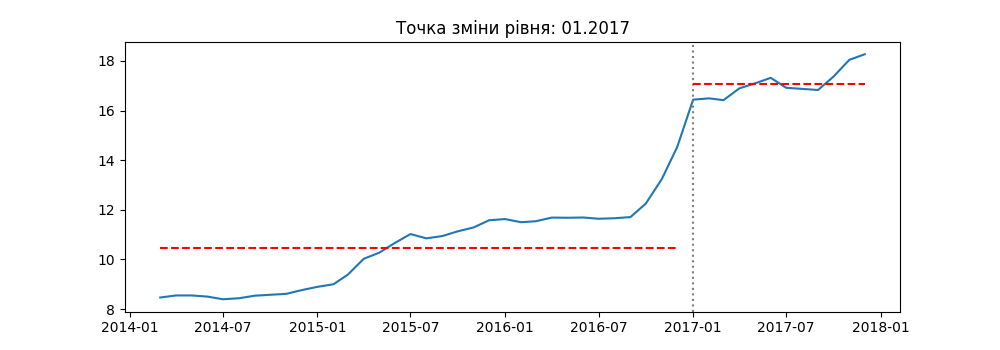

In [10]:
# Завдання 8. Точка зміни режиму
from scipy import stats

def scan(x, min_seg=6):
    out = []
    for k in range(min_seg, len(x) - min_seg + 1):
        t = stats.ttest_ind(x[k:], x[:k], equal_var=False)
        out.append((k, t.statistic, t.pvalue, x[:k].mean(), x[k:].mean()))
    return pd.DataFrame(out, columns=['k', 't', 'p', 'до', 'після'])

sc = scan(v)
best_row = sc.loc[sc['t'].abs().idxmax()]
k0 = int(best_row['k'])
CP = GRID[k0]

print('Точка зміни:', CP.strftime('%m.%Y'))
print('t =', round(best_row['t'], 2), '| середнє до:', round(best_row['до'], 2), '| після:', round(best_row['після'], 2))
print('p-value:', round(best_row['p'], 4))
print('Статистично значуща зміна:', 'так' if best_row['p'] < 0.05 else 'ні')

plt.figure(figsize=(10, 3.5))
plt.plot(y)
plt.axvline(CP, color='grey', ls=':')
plt.hlines([best_row['до'], best_row['після']], [GRID[0], CP], [GRID[k0 - 1], GRID[-1]], color='red', ls='--')
plt.title('Точка зміни рівня: ' + CP.strftime('%m.%Y'))
plt.show()

**Висновок до завдання 8:**

1. Графік наведено вище.
2. Точка - 01.2017, t = 20.38, середнє до - 10.45 грн, після - 17.08 грн (+63 %).
3. Звичайний t-тест показав статистично значущу різницю між середніми (p-value < 0.05). Однак це значення не враховує перебір багатьох можливих дат, тому результат слід інтерпретувати обережно.
4. Це не сезонний сплеск: рівень не повернувся (на графіку всі значення після точки вищі за всі значення до неї) і такий підйом не повторюється в інші роки.

## Завдання 9. Рецензія на чужий аналіз

Відкрийте `ЛР4_помилковий_аналіз.ipynb`. Це звіт, зроблений на іншому ряді з того самого набору.
Він виконується без помилок і виглядає переконливо, але містить **методологічні помилки**.

**У звіті наведіть:**
1. перелік знайдених помилок — для кожної вкажіть номер клітинки, суть помилки й **чим вона небезпечна**;
2. для трьох найсерйозніших — як саме їх виправити.

> 💡 **Підказка.** Помилок щонайменше вісім. Шукайте не синтаксис, а порушення принципів роботи з часовими рядами.

In [11]:
# Завдання 9. Рецензія на чужий аналіз

**Висновок до завдання 9:**

Рецензований ряд — гречка, Вінниця. Клітинки нумеровано з 1.

| № | Помилка | Чим небезпечна |
|---|---|---|
| 1 | Сітку не застосовано - пропуск 08.2017 не помічено | Усі зсуви й моделі після 08.2017 зміщені на місяць |
| 2 | Подорожчання за двома крайніми точками; висновок про купівельну спроможність | Залежить від вибору точок; доходів у даних немає |
| 3 |Порівняння MAE товарів різного масштабу | Висновок перевернутий: у % гречка гірша (6.2 % проти 1.9 %) |
| 4 | Кореляція рівнів (r = 0.996) як доказ причинності | Хибна кореляція через спільний тренд |
| 5 | "STL виділив сезонність, отже вона є" | STL завжди її виділяє; $F_S$ = 0.26 - сезонності немає |
| 6 | Переплутано напрямок ADF ($p$ = 0.233 - нестаціонарний); зайва друга різниця; немає KPSS | Хибний порядок інтегрування |
| 7 | Поріг 1.3σ замість заявлених 2σ, z від середнього ряду з трендом | "Аномалії" - просто початок і кінець тренду (при 2σ їх 0) |
| 8 | Випадковий train_test_split, тест відсортовано за значенням | Витік майбутнього; MAE не має сенсу |
| 9 | Немає порівняння з базисом | Неможливо оцінити, чи модель корисна |
| 10 | Прогноз неперевіреною ARIMA(2,2,1) без інтервалів | Ілюзія точності, "вибуховий" тренд |
| 11 |  Стовпці з обрізаною віссю Y | Візуальне перебільшення змін |

**Як виправити три найсерйозніші:**
1. № 8–9: замінити випадковий поділ на рухомий початок і порівнювати модель з базисами на тих самих фолдах.
2. № 6: правильно читати ADF, додати KPSS, взяти одну різницю й обрати модель за ACF/PACF.
3. № 1: одразу зробити reindex(grid), показати й заповнити пропуск 08.2017.

## Завдання 10. Експорт ряду для Orange

Збережіть підготовлений ряд у файл `ряд_для_orange.csv` **рівно у такому вигляді**:

| Стовпець | Тип | Зміст |
|---|---|---|
| `date` | текст у форматі `РРРР-ММ-ДД` | перше число місяця |
| `price` | число | ціна, пропуск уже заповнений |

Один рядок на місяць, 46 рядків плюс заголовок, роздільник — кома, кодування UTF-8.

**У звіті наведіть:**
1. підтвердження, що файл має 46 рядків даних і не містить порожніх значень.

> 💡 **Підказка.** Формат заданий жорстко: Orange має отримати **точно ті самі** дані, що й Python, інакше порівняння в Частині 2 втрачає сенс.

In [12]:
# Завдання 10. Експорт ряду для Orange
OUT = 'ряд_для_orange.csv'
pd.DataFrame({'date': y.index.strftime('%Y-%m-%d'), 'price': y.values}).to_csv(OUT, index=False, encoding='utf-8')

check = pd.read_csv(OUT)
print('46 рядків:', len(check) == 46)
print('Правильні стовпці:', list(check.columns) == ['date', 'price'])
print('Порожніх значень:', check.isna().sum().sum())

46 рядків: True
Правильні стовпці: True
Порожніх значень: 0


**Висновок до завдання 10:**

Файл ряд_для_orange.csv має 46 рядків даних + заголовок, порожніх значень 0, дані збігаються з рядом у Python.

---
# ЧАСТИНА 2. Той самий аналіз засобами Orange

*Виконується самостійно.*

Потрібен додаток **Timeseries**: у Orange відкрийте *Options → Add-ons…* і встановіть `Orange3-Timeseries`.

**Головна умова цієї частини:** Orange має отримати **ті самі дані** й **ті самі налаштування перевірки**,
що й Python у Частині 1. Тоді будь-яка розбіжність у числах пояснюється **лише означеннями метрик**,
а не різними даними чи різними моделями. Саме це вам і треба довести.

## Завдання 11. Потік опрацювання даних

Побудуйте в Orange потік:

`File` → `As Timeseries` → `Interpolate` → `Line Chart`

У віджеті **File** завантажте свій `ряд_для_orange.csv`; переконайтеся, що `date` розпізнано
як **time**, а `price` — як **numeric**. У віджеті **As Timeseries** оберіть `date` як часову змінну.

**У звіті наведіть:**
1. знімок екрана з побудованим потоком;
2. знімок `Line Chart` із вашим рядом;
3. підтвердження, що графік у Orange збігається з графіком із завдання 3.

> 💡 **Підказка.** Якщо `date` розпізнано як текст, поверніться до завдання 10 і перевірте формат дати.

In [13]:
# Завдання 11. Потік опрацювання даних

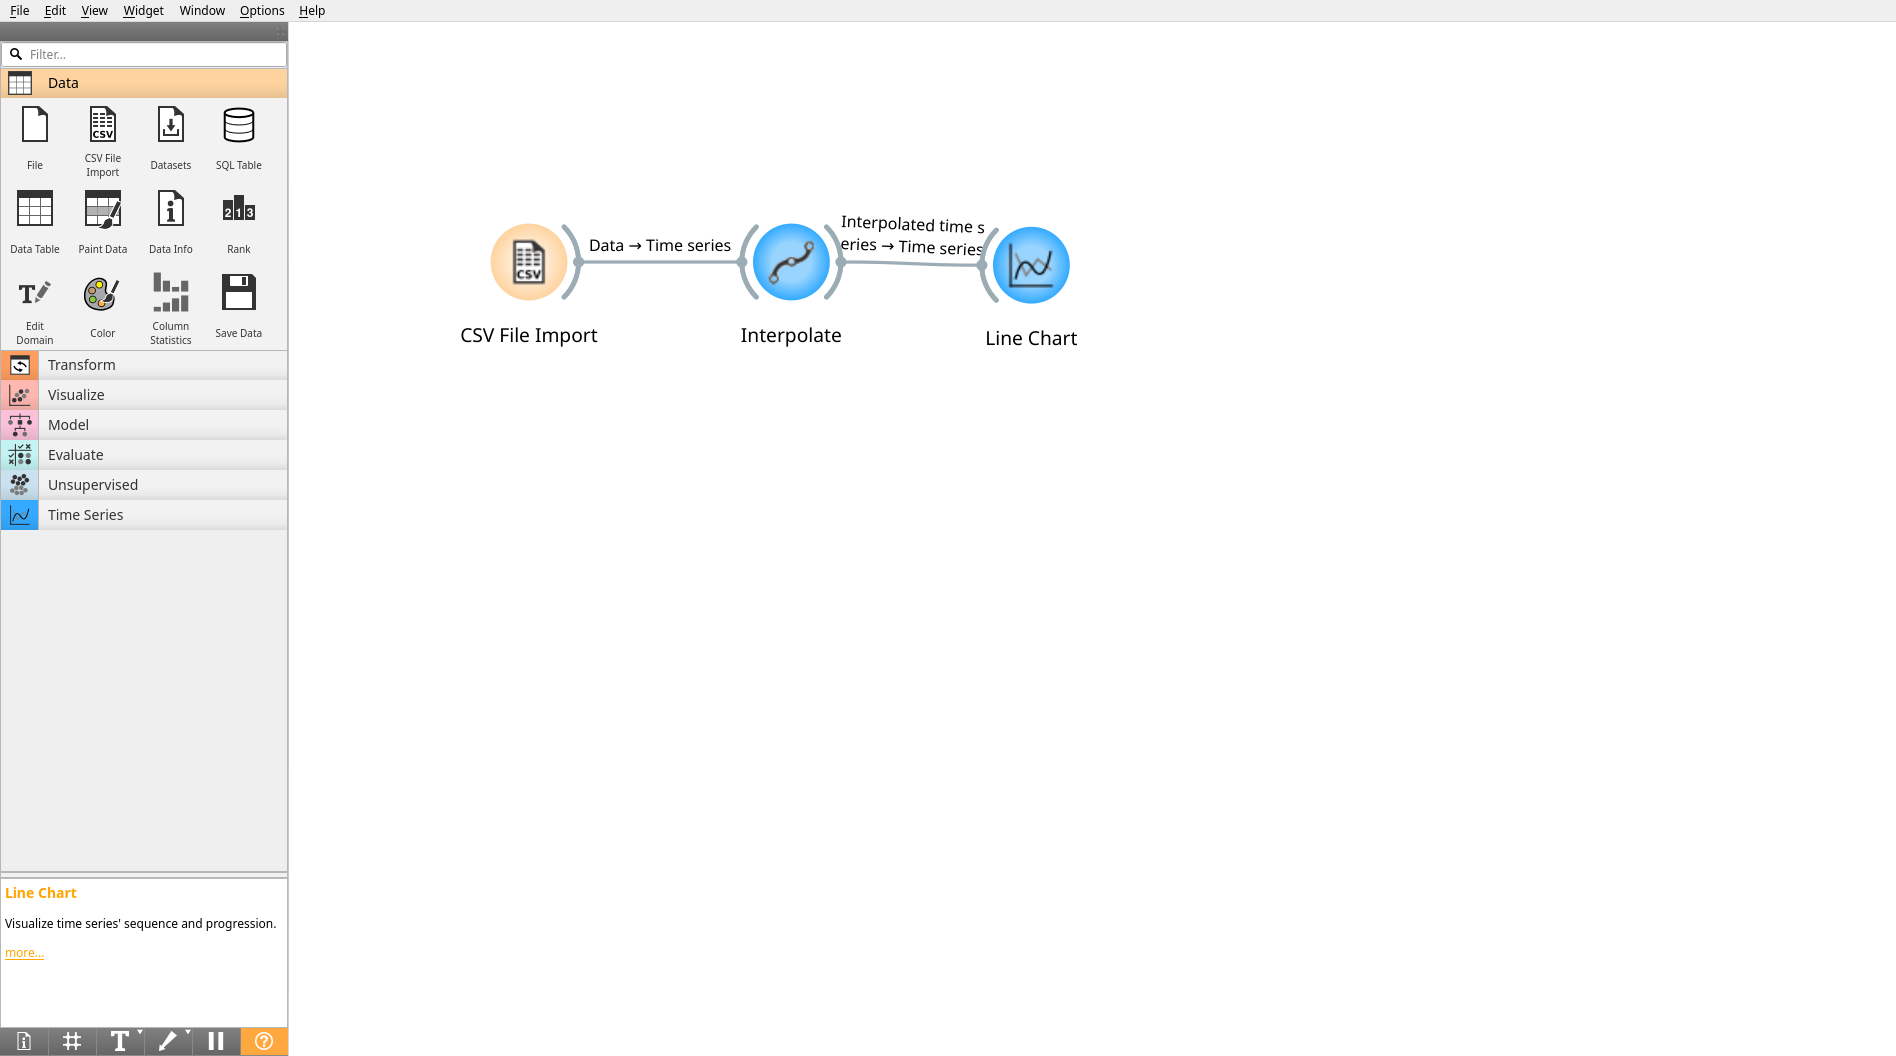

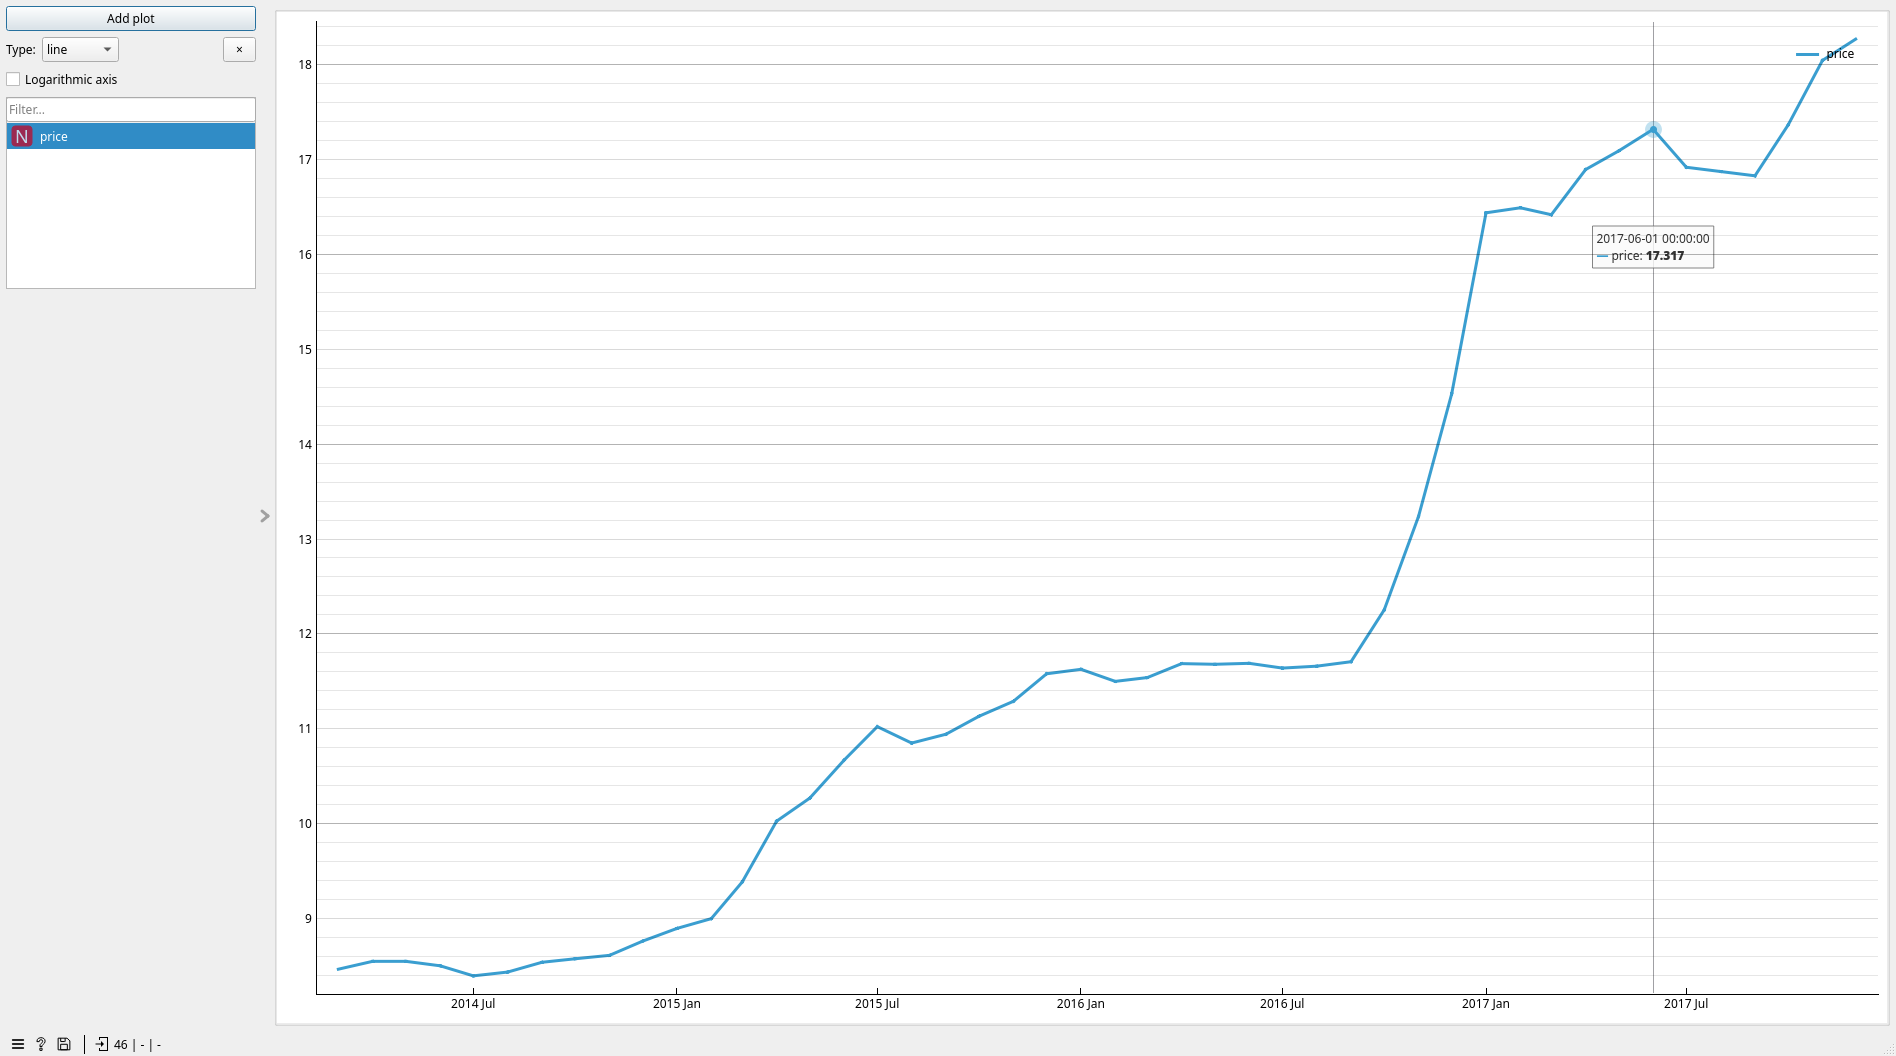

**Висновок до завдання 11:**

Побудований графік порівняно з графіком із завдання 3. Збіг часових міток і значень ціни підтверджує, що Orange використовує той самий часовий ряд, що й Python.

## Завдання 12. Автокореляція та диференціювання

Додайте до потоку віджети `Correlogram`, `Difference` та `Seasonal Adjustment`.

**У звіті наведіть:**
1. знімок корелограми;
2. зіставлення з ACF із завдання 5: **чи збігаються висновки** про значущі лаги;
3. знімок сезонно скоригованого ряду та порівняння з сезонною складовою STL із завдання 4.

> 💡 **Підказка.** Orange і statsmodels рахують автокореляцію однаково — якщо картина різна, перевірте, чи однакові дані на вході.

In [14]:
# Завдання 12. Автокореляція та диференціювання

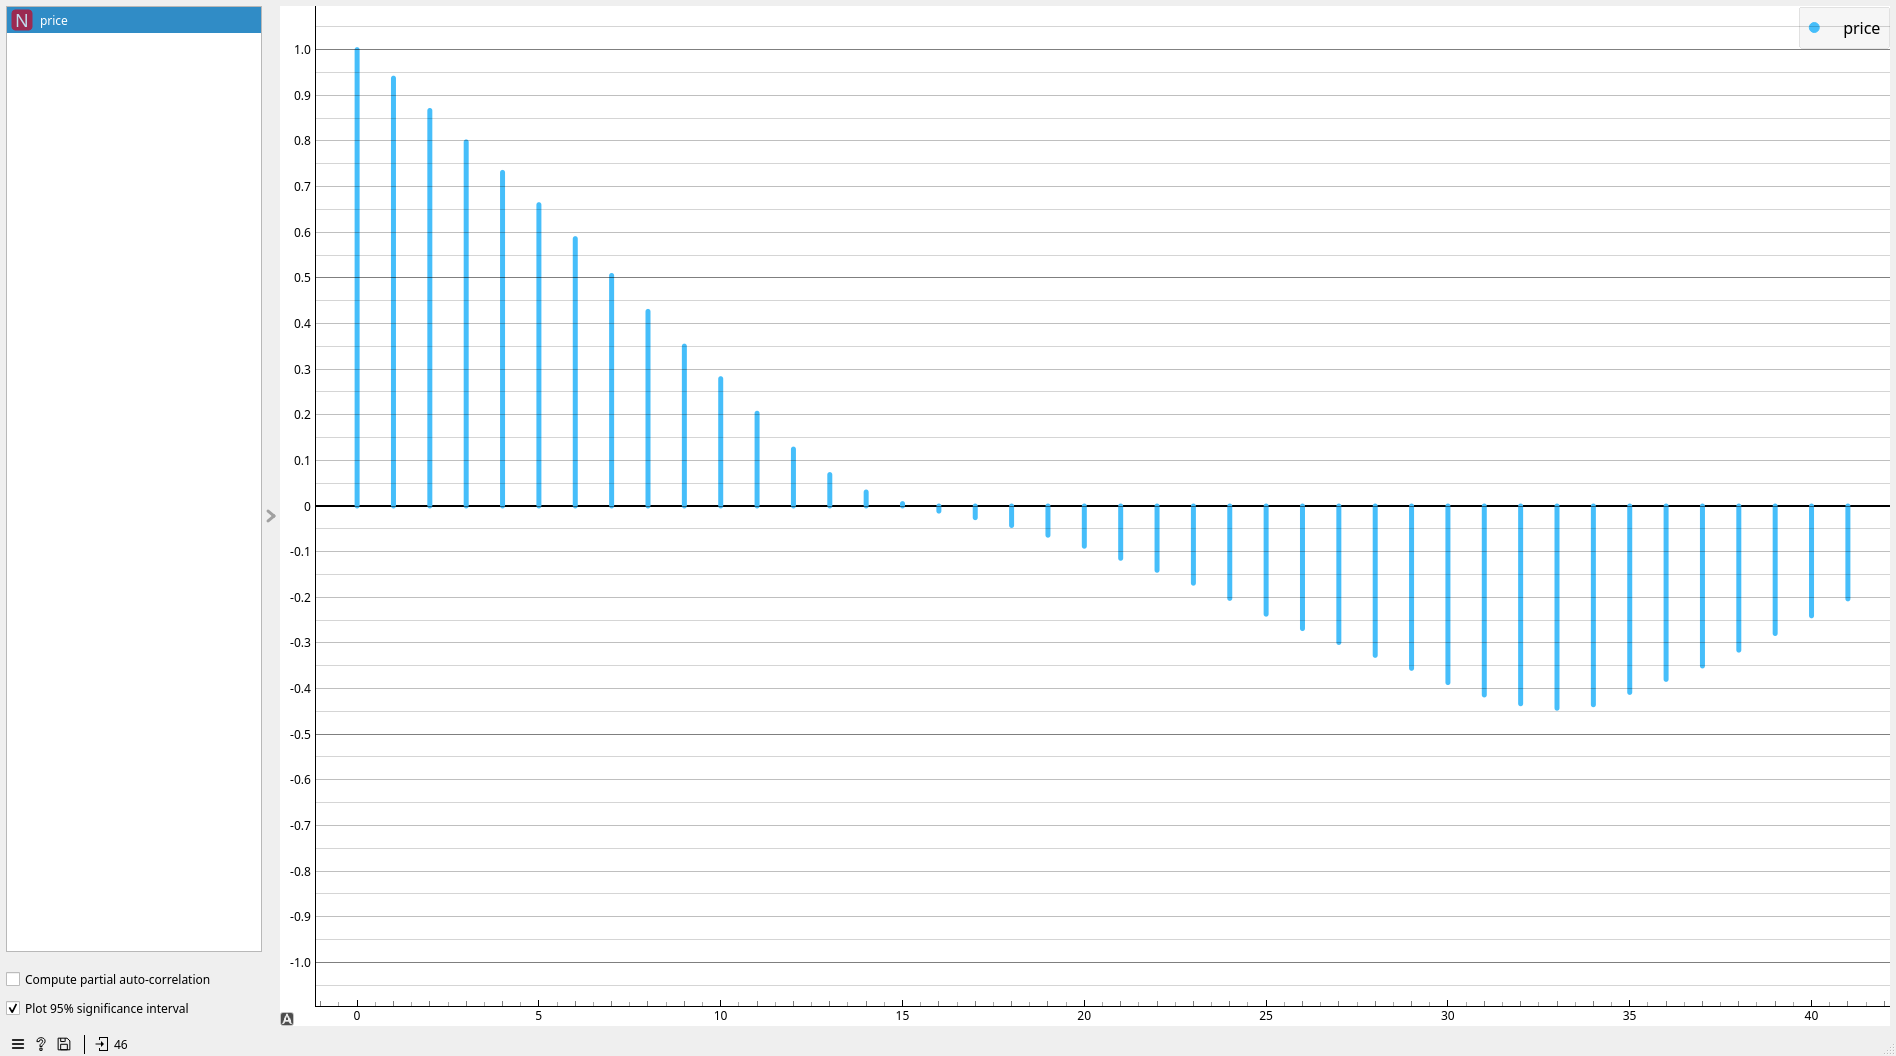

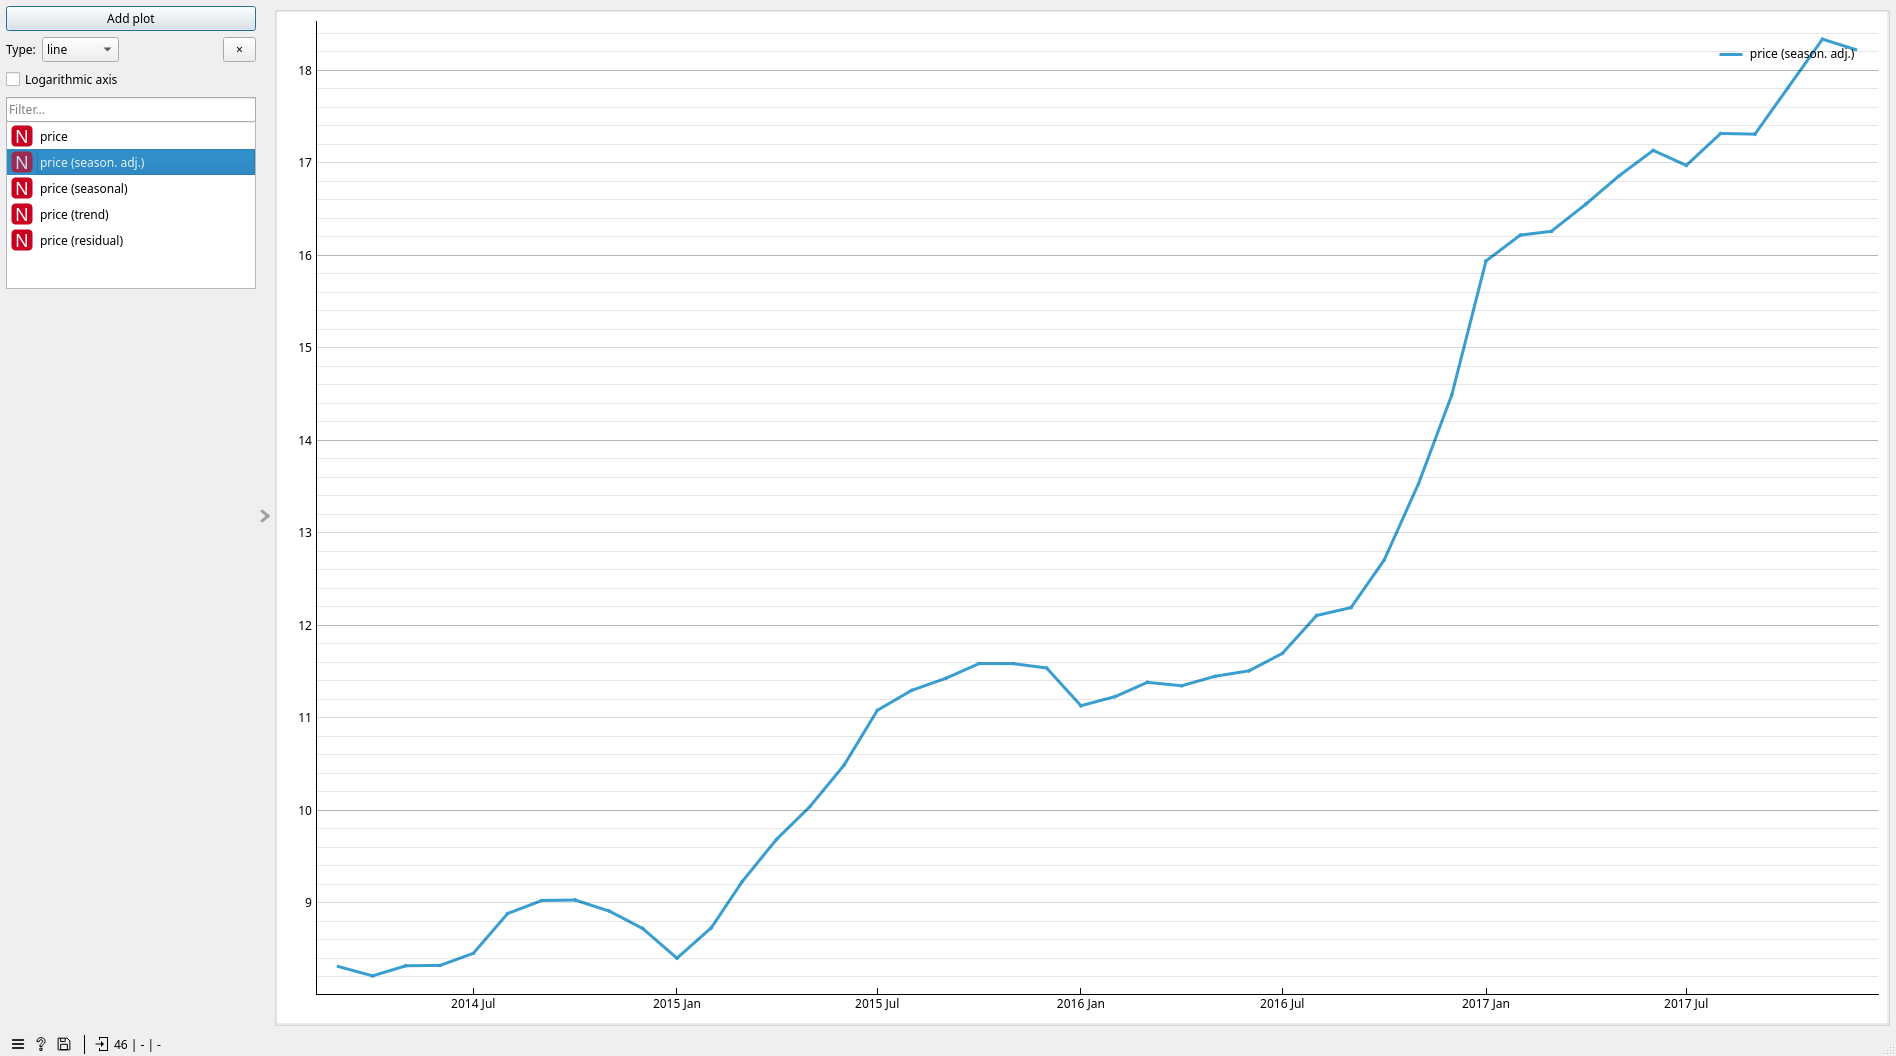

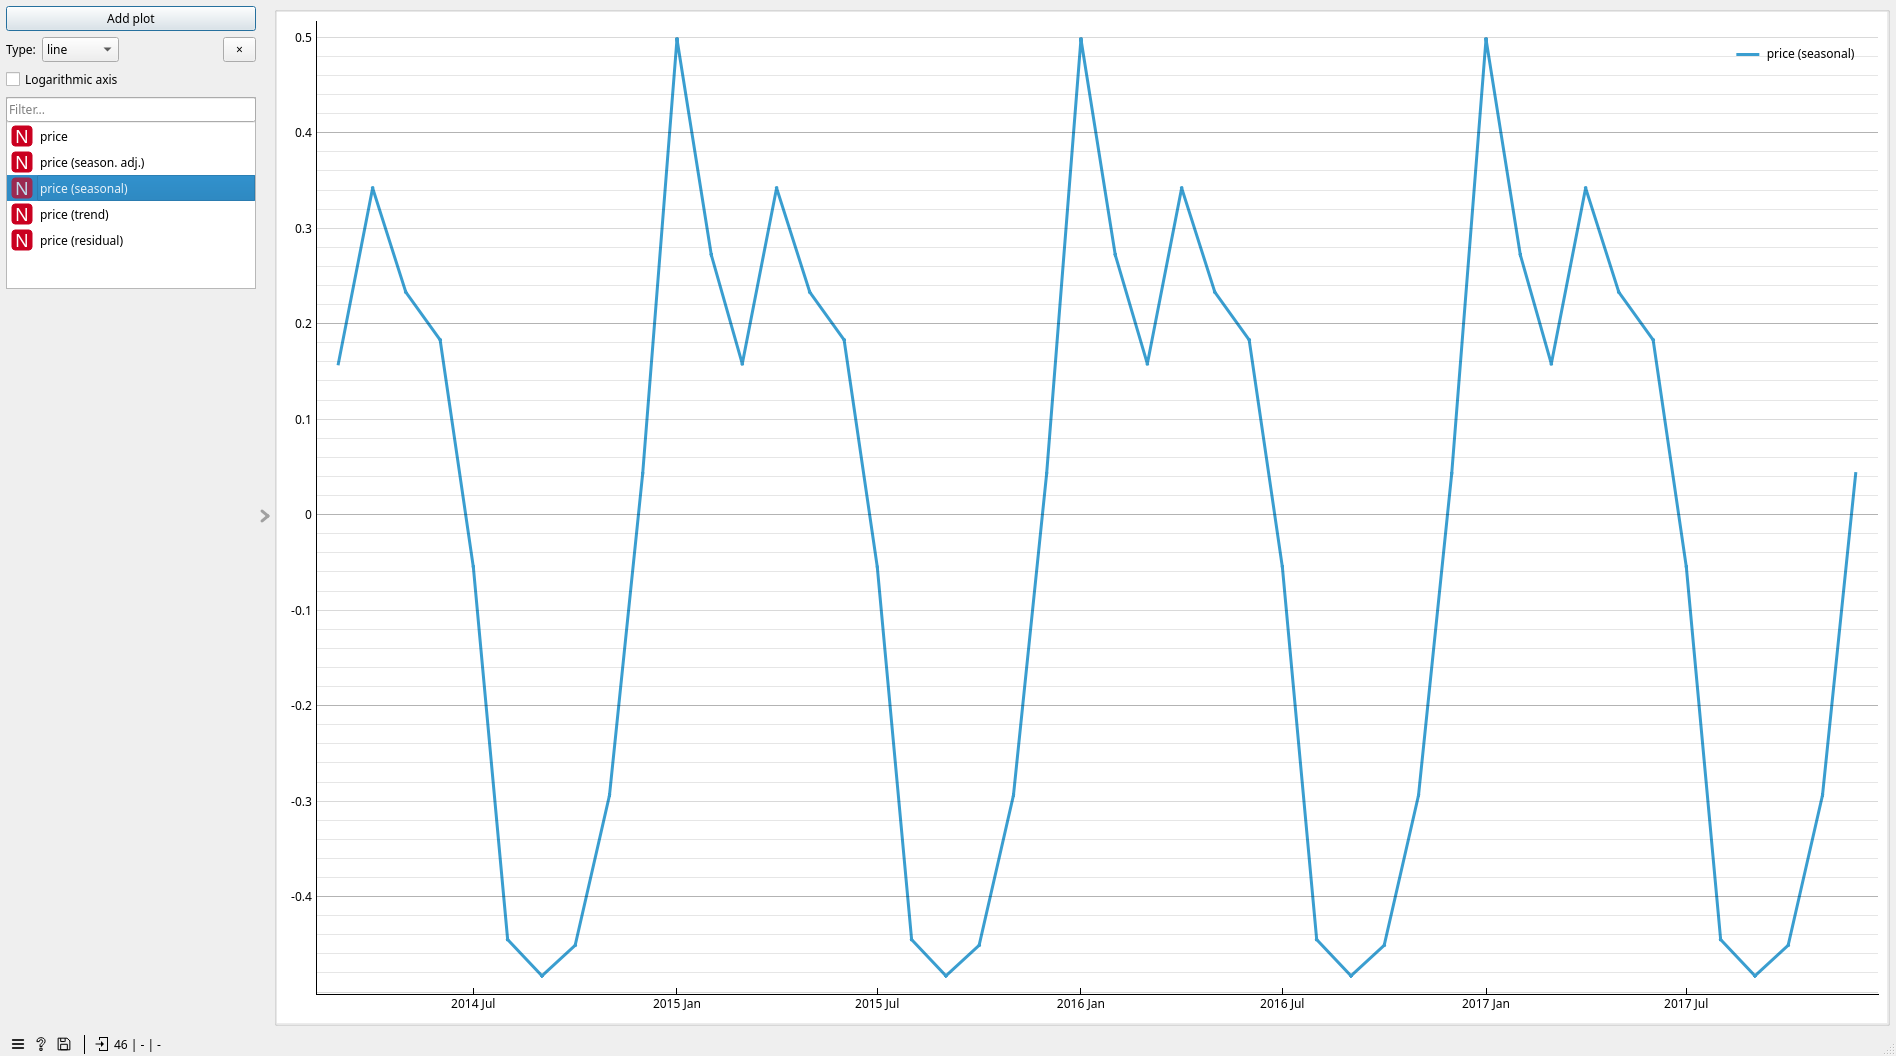

**Висновок до завдання 12:**

1. Корелограму вихідного ряду з Orange наведено вище.
2. Висновки збігаються з завданням 5. Значення ACF в Orange такі самі, як у Python: 0.94, 0.87, 0.80, 0.73 на лагах 1–4, тобто Orange отримав ті самі дані. В обох середовищах ACF спадає повільно й майже лінійно, і значущими є багато перших лагів.
3. Seasonal Adjustment в Orange - класичне адитивне розкладання з періодом 12. Його сезонна складова однакова щороку: від +0.50 грн у січні до -0.48 грн у вересні, розмах ≈ 1 грн. Сезонна складова STL завдання 4, навпаки, змінюється з року в рік, бо вбирає стрибок 2016 року. Сезонно скоригований ряд в Orange майже не відрізняється від вихідного: на ньому той самий тренд і той самий стрибок 10.2016 - 01.2017. Отже, сезонна поправка (±0.5 грн) мала порівняно з рівнем ціни (8–18 грн), що підтверджує висновок завдання 4: значущої сезонності немає.

## Завдання 13. Модель і оцінювання

Додайте `ARIMA Model` з порядком **(1, 1, 1)** та `Model Evaluation`.

У віджеті **Model Evaluation** встановіть **Number of folds = 7** та **Forecast steps = 3**.

**У звіті наведіть:**
1. знімок таблиці Model Evaluation з усіма метриками;
2. **що станеться, якщо лишити типові налаштування** (20 фолдів × 3 кроки) — наведіть повідомлення, яке видасть Orange, і поясніть, звідки воно береться;
3. які саме 7 фолдів перевіряє Orange — тобто на яких відрізках ряду навчається модель.

> 💡 **Підказка.** Orange відмовиться працювати при типових налаштуваннях. Це не збій, а наслідок довжини вашого ряду — порахуйте, якої саме.

In [15]:
# Завдання 13. Модель і оцінювання

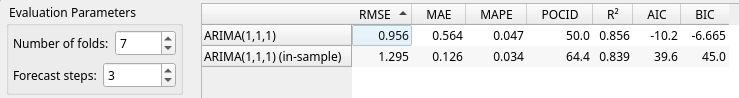

**Висновок до завдання 13:**

1. Таблицю Model Evaluation для ARIMA(1,1,1) на 7 фолдах x 3 кроки наведено вище: RMSE збігається з пайтоном, а інші метрики ні
2. З типовими налаштуваннями (20 фолдів x 3 кроки) Orange видає помилку: "Supplied time series is too short for this many folds / step size. Retry with fewer iterations." Причина - довжина ряду: Orange вимагає, щоб фолди x кроки + max(p, d, q) не перевищувало довжину ряду. Для 20 x 3 це 60 + 1 = 61 > 46, а для 7 x 3 - 21 + 1 = 22 <= 46.
3. Фолди Orange: у фолді k модель навчається на всьому ряді, крім останніх k*3 місяців, і прогнозує наступні 3. Це ті самі 7 відрізків, що й у пайтоні (там вони пронумеровані від найранішого):

   | фолд | навчання | тест |
   |---|---|---|
   | 1 | 03.2014 - 09.2017 (43 міс.) | 10-12.2017 |
   | 2 | 03.2014 - 06.2017 (40) | 07-09.2017 |
   | 3 | 03.2014 - 03.2017 (37) | 04-06.2017 |
   | 4 | 03.2014 - 12.2016 (34) | 01-03.2017 |
   | 5 | 03.2014 - 09.2016 (31) | 10-12.2016 |
   | 6 | 03.2014 - 06.2016 (28) | 07-09.2016 |
   | 7 | 03.2014 - 03.2016 (25) | 04-06.2016 |

## Завдання 14. Чому числа не збігаються

Порівняйте метрики Orange з метриками, які ви отримали в Частині 1 для **тієї самої** моделі
ARIMA(1,1,1) на **тих самих** 7 фолдах.

Для кожної з чотирьох метрик Orange — `RMSE`, `MAE`, `MAPE`, `POCID` — **відтворіть її значення в Python**,
тобто напишіть формулу, за якою Orange отримав саме це число, і переконайтеся, що ваш розрахунок
збігається з таблицею Orange до третього знака.

**У звіті наведіть:**
1. таблицю на чотири рядки: метрика · значення Orange · ваше відтворення в Python · формула;
2. **яка з метрик не відповідає своїй назві** — і чим саме вона відрізняється від того, що зазвичай позначають цією абревіатурою;
3. яка метрика збіглася між середовищами одразу і чому;
4. висновок: що саме треба перевіряти, перш ніж порівнювати числа з двох різних інструментів.

> 💡 **Підказка.** Жодна з розбіжностей не є помилкою Orange. Усі формули відкриті — шукайте їх у вихідному коді додатка Timeseries, файл `functions.py`.

In [16]:
# Завдання 14. Чому числа не збігаються
true, pred = [], []
for k in range(1, N_FOLDS + 1):
    end = len(v) - k * H
    true += list(v[end:end + H]); pred += list(fit_arima(v[:end], (1, 1, 1)).forecast(H))
true, pred = np.array(true), np.array(pred)
e = true - pred

pd.DataFrame({
    'Orange': [0.956, 0.564, 0.047, 50.0],
    'Python, формула Orange': [np.sqrt(np.mean(e ** 2)), np.median(np.abs(e)),
                               np.mean(np.abs(e)) / np.mean(np.abs(true)),
                               100 * np.mean(np.diff(true) * np.diff(pred) > 0)],
    'Python, частина 1': [np.sqrt(np.mean(e ** 2)), np.mean(np.abs(e)), np.mean(np.abs(e / true)), np.nan],
}, index=['RMSE', 'MAE', 'MAPE', 'POCID']).round(3)

,Orange,"Python, формула Orange","Python, частина 1"
RMSE,0.956,0.956,0.956
MAE,0.564,0.564,0.706
MAPE,0.047,0.047,0.045
POCID,50.000,50.000,NaN


**Висновок до завдання 14:**

1. Відтворення метрик Orange:

   | метрика | Orange | Python | формула в Orange |
   |---|---|---|---|
   | RMSE | 0.956 | 0.956 | $\sqrt{\frac{1}{n}\sum e_t^2}$ |
   | MAE | 0.564 | 0.564 | $\text{median}\,\lvert e_t\rvert$ |
   | MAPE | 0.047 | 0.047 | $\frac{1}{n}\sum \lvert e_t\rvert \,/\, \frac{1}{n}\sum \lvert y_t\rvert$ (частка, не %) |
   | POCID | 50.0 | 50.0 | $100 \cdot \frac{1}{n-1}\sum [\Delta y_t \cdot \Delta \hat y_t > 0]$ |

2. Назві не відповідає MAE: в Orange це медіана абсолютної похибки (у коді прямо написано Median absolute error), а не середнє. MAPE теж нестандартна: це не середнє відсоткових похибок, а MAE, поділена на середній рівень ряду, ще й як частка. Тому 0.047 ≠ 4.50 %.
3. Одразу збігся RMSE: формула стандартна, а прогнози ті самі. Порядок точок на нього не впливає. POCID теж має пастку: Orange рахує його по склеєних фолдах у зворотному порядку, враховуючи й переходи між фолдами. У хронологічному порядку вийшло б 40 %, а не 50 %.
4. Перш ніж порівнювати числа з двох інструментів, треба перевірити: (а) ті самі дані; (б) ті самі фолди, горизонт і модель; (в) точну формулу кожної метрики - середнє чи медіана, % чи частка, як склеюються фолди. Однакова абревіатура не гарантує однакового означення, тому формули слід читати у вихідному коді.

## Завдання 15. Матриця напрямку зміни

Метрика `POCID` у Orange вимірює, чи правильно модель передбачає **напрямок** зміни ціни.
Розгорніть її в таблицю 2×2: рядки — що сталося насправді (зросла / впала),
стовпці — що передбачила модель.

**У звіті наведіть:**
1. заповнену матрицю 2×2 для вашої моделі;
2. перевірку, що частка правильних передбачень збігається зі значенням POCID із Orange;
3. висновок: чи корисна ваша модель для рішення «купувати зараз чи чекати», і чому це **інше питання**, ніж те, на яке відповідають MAE та RMSE.

> 💡 **Підказка.** Ця матриця — часоворядовий відповідник матриці похибок із класифікації.

In [17]:
# Завдання 15. Матриця напрямку зміни
actual = np.where(np.diff(true) > 0, 'зросла', 'впала')
predicted = np.where(np.diff(pred) > 0, 'зросла', 'впала')
matrix = pd.crosstab(actual, predicted, rownames=['насправді'], colnames=['прогноз'])
print(matrix)
print('Частка правильних напрямків, %:', round(100 * np.mean(actual == predicted), 1))
print('Частка місяців зі зростанням, %:', round(100 * np.mean(actual == 'зросла'), 1))

прогноз    впала  зросла
насправді               
впала          4       5
зросла         5       6
Частка правильних напрямків, %: 50.0
Частка місяців зі зростанням, %: 55.0


**Висновок до завдання 15:**

1. Матриця напрямку зміни (20 пар сусідніх точок із 21 тестової):

   | насправді \ прогноз | впала | зросла |
   |---|---|---|
   | впала | 4 | 5 |
   | зросла | 5 | 6 |

2. Правильних передбачень: 4 + 6 = 10 із 20 = 50 %, що збігається з POCID = 50.0 з Orange.
3. Для рішення "купувати зараз чи чекати" модель не корисна: вона вгадує напрямок не краще за монетку і навіть гірше за просте правило "ціна завжди росте". MAE та RMSE відповідають на інше питання: наскільки прогноз відхиляється від ціни. Для ряду з сильним трендом прогноз може бути близьким за рівнем, але помилятися щодо напрямку наступної зміни. Для рішення про покупку важливий саме напрямок, тож ця модель тут не допомагає.

---
# Загальний висновок

Напишіть 8–12 речень, які відповідають на такі питання:

1. Чи є у вашому ряді сезонність і чим ви це довели?

   Значущої сезонності в ряді немає. STL формально дав F_S = 0.76, вище порогу 0.64, але сезонна складова з року в рік зростає, бо в неї потрапив стрибок 2016 року. Крім того, ACF різниці на лагу 12 незначуща, а сезонний наївний прогноз програє простому наївному.

2. Який метод прогнозування виявився найкращим і чи перевершив він найпростіший базис?

   Найкращим базисом став дрейф (MAE 0.737). ARIMA(1,1,1) дала MAE 0.706, тобто лише трохи краще, тому складніша модель практично не перевершила простий базис.

3. Чи знайшли ви точку зміни режиму; якщо так — чи є для неї зовнішнє пояснення?

   Так, у 01.2017: середня ціна зросла з 10.45 до 17.08 грн і вже не повернулася. Можливе пояснення - подвоєння мінімальної зарплати з січня 2017 року, але на цих даних це лише гіпотеза.

4. Чому однаково названі метрики у двох середовищах дали різні числа?

   Не через дані чи модель (RMSE збігся точно), а через різні формули: MAE в Orange - це медіана похибки, MAPE рахується як частка від середнього рівня ряду, а POCID - по фолдах у зворотному порядку.

5. Чого ви не змогли встановити через те, що ряд має лише 46 спостережень?

   Не вдалося надійно відрізнити слабку сезонність від разового стрибка, а перевага ARIMA над дрейфом на 21 тестовій точці не доведена.

---
# Критерії оцінювання

| Бали | Умова |
|---|---|
| **0** | Ряд не розкладено або прогноз не побудовано. Робота не зарахована. |
| **2** | Виконано лише Частину 1: ряд розкладено й прогноз побудовано, але в Orange аналіз не відтворено. |
| **3** | Виконано обидві частини, проте прогноз не зіставлено з наївним базисом, а розбіжність результатів двох середовищ не пояснено. |
| **4** | Ряд розкладено на складові; прогноз зіставлено з наївним базисом за ретроспективною перевіркою з рухомим початком; той самий аналіз відтворено в Orange; зіставлено результати двох середовищ і пояснено розбіжність метрик. |

**Знімаються бали за:**

* графіки без пояснення вибору геометрії та шкали;
* числа без письмового висновку;
* прогноз без порівняння з базисом;
* висновок «метрики різні, бо середовища різні» без відтворення формул;
* зошит, який не виконується від початку до кінця.

---
# Декларація про використання штучного інтелекту

Використання інструментів штучного інтелекту під час виконання цієї роботи **дозволено**.
Умова одна: ви маєте розуміти кожен рядок зданого коду й кожне написане твердження
і бути готовим пояснити їх на захисті.

Заповніть таблицю. Якщо ШІ не використовувався, напишіть «не використовувався» в першому рядку
й залиште решту порожньою.

| Питання | Ваша відповідь |
|---|---|
| Які інструменти використано (назва, версія) | Claude Opus 5.5/medium|
| Для яких саме завдань | Пофіксити баг з orange, помогти із розумінням всіх завдань|
| Що саме було згенеровано (код / текст / пояснення / виправлення помилок) | пояснення |
| Що ви змінили у згенерованому результаті й чому | ші часто пише забагато тесту, тому скорочував непотрібні для лабораторної резульатти |
| Що з отриманого ви **перевірили самостійно** і яким способом | перевірив абсолютно усе, перечитуючи код та питаючись ші, як він це зробив |
| Чи траплялися у відповідях ШІ помилки; якщо так — які | галюцинував і генерував забагато сміття |

**Підтверджую, що розумію весь зданий код і всі зроблені висновки
та можу пояснити будь-яку їх частину на захисті роботи.**

Підпис: ЗШ  Дата: 26 жовтня